## Churn Analysis and Customer Intelligence

#####                       *by Rishabh Mishra (Sr Data Analyst with 7+ Years of Experience)*

> **Credits:** This project is based on a guided *Churn Analysis and Customer Intelligence* walkthrough by Rishabh Mishra. The dataset comes from that guided project. Homework items are completed and **Section 5 (Additional Analysis)** is added by Karan Shinde.

In [1]:
# Churn Analysis and Customer Intelligence

In [2]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

## 1. Import database / data  

In [3]:
# NOTE:
# If you encounter any issues importing the customer_churn.db file,
# run the code below to create the database locally from the provided Excel file OR, can directly import data & start working.

# Otherwise, skip this step and proceed to the next section: Data Import

# Excel file path
excel_file = 'customer_churn_data_raw.xlsx'

# Create SQLite database connection
conn = sqlite3.connect('customer_churn.db')

# Read all sheet names from Excel file
excel_data = pd.ExcelFile(excel_file)

# Loop through each sheet and store as separate table
for sheet in excel_data.sheet_names:
    df = pd.read_excel(excel_file, sheet_name=sheet) # Read sheet into dataframe
    # Write dataframe to SQLite table
    df.to_sql(
        name=sheet,          # Table name = Sheet name
        con=conn,
        if_exists='replace', # Replace table if already exists
        index=False
    )

# Close connection
conn.close()

print("All sheets successfully converted into SQLite tables.")

All sheets successfully converted into SQLite tables.


In [4]:
# Data Import: db file to pandas, storing each table to a separate df

# Connect to SQLite database
conn = sqlite3.connect('customer_churn.db')

# sql query to Get all table names
sql_query = """
        SELECT name
        FROM sqlite_master
        WHERE type='table';
"""

# read sql query in pandas
tables = pd.read_sql(sql_query, conn)

# create dataframe for each table
for table_name in tables['name']:
    df = pd.read_sql(f"SELECT * FROM {table_name}", conn) # Read table into dataframe
    globals()[f"df_{table_name}"] = df                    # Create dynamic dataframe name
    print(f"Created dataframe: df_{table_name}")

# Close connection
conn.close()

Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [5]:
# Print table names and column names
conn = sqlite3.connect('customer_churn.db')

for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")
    # Get column information
    columns_query = f"PRAGMA table_info({table_name});"
    columns = pd.read_sql(columns_query, conn)
    print("Columns:")
    print(columns['name'].tolist())

# Close connection
conn.close()


Table Name: db_customer
Columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
Columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [6]:
# PRAGMA is a special command in SQLite used to:
# inspect db information, control db settings, retrieve metadata about tables

## 2. Data cleaning

In [7]:
# df_db_customer.head() # customer table
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
695,0696-TMNGR,kavya,India,Nagaland,Male,1979-04-10 00:00:00,NaN,None
696,0697-LYERE,sahil,India,Meghalaya,Female,1985-09-09 00:00:00,NaN,None
697,0698-EHIYD,neha,India,Nagaland,Men,1997-12-25 00:00:00,NaN,None
698,0699-TELPF,amit,India,Karnataka,Male,1997-08-08 00:00:00,NaN,None
699,0700-VXWEU,neha,India,Nagaland,Male,1992-08-19 00:00:00,travel,None


In [8]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  700 non-null    str   
 1   name        700 non-null    str   
 2   country     697 non-null    str   
 3   state       700 non-null    str   
 4   gender      700 non-null    str   
 5   dob         700 non-null    str   
 6   interests   459 non-null    str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 43.9+ KB


In [9]:
# a. rename col - name to customer_name
# b. drop columns - interest and pincode
# c. change data type - dob
# d. data standardization - gender
# e. fix missing values (using existing data) - country

#### a. Rename Col

In [10]:
# a. rename col - name to customer_name

df_db_customer.rename(columns = {'name' : 'customer_name'}, inplace= True)

#### b. Drop columns

In [11]:
# b. drop columns - interest and pincode

# df_db_customer.drop(df_db_customer.columns[-2:], axis=1)
# df_db_customer.drop(df_db_customer.columns[6:], axis=1)

df_db_customer.drop(columns=['interests', 'pincode'], inplace=True)  # using col name

In [12]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerid     700 non-null    str  
 1   customer_name  700 non-null    str  
 2   country        697 non-null    str  
 3   state          700 non-null    str  
 4   gender         700 non-null    str  
 5   dob            700 non-null    str  
dtypes: str(6)
memory usage: 32.9 KB


#### c. Change data type

In [13]:
# c. change data type - dob

df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

#### d. Data standardization

In [14]:
# d. data standardization - gender

# df_db_customer['gender'].unique()
df_db_customer['gender'] = df_db_customer['gender'].replace({'Men' : 'Male', 'Women' : 'Female'})

In [15]:
df_db_customer['gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

#### e. Fix missing values

In [16]:
# e. fix missing values - country

# df_db_customer['country'].isna().sum()
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01


In [17]:
# country and state - unique value pair

# Creating state → country map from non-null rows
state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

# Fill the missing country using State
df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [18]:
df_db_customer[df_db_customer['country'].isna()] # no null value in country col

,customerid,customer_name,country,state,gender,dob


In [19]:
df_db_subscription.head() # subcription table

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15 00:00:00,Refferal,2025-03-15 00:00:00,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01 00:00:00,Paid,2024-08-01 00:00:00,Premium,Annual,2024-09-10 00:00:00,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20 00:00:00,Organic,2025-11-20 00:00:00,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10 00:00:00,Paid,2025-05-10 00:00:00,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05 00:00:00,Refferal,2024-01-05 00:00:00,Standard,Monthly,2024-02-28 00:00:00,Too expensive,13.99,195,88


In [20]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               700 non-null    str    
 1   subscription_start_date  700 non-null    str    
 2   subscription_type        700 non-null    str    
 3   renewal_date             700 non-null    str    
 4   plan_type                700 non-null    str    
 5   contract_type            700 non-null    str    
 6   cancellation_date        170 non-null    str    
 7   cancellation_reason      170 non-null    str    
 8   monthly_charges          700 non-null    float64
 9   cltv                     700 non-null    int64  
 10  churn_score              700 non-null    int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 60.3 KB


In [21]:
# change data type to date - subscription_start_date , renewal_date, cancellation_date
date_col = ['subscription_start_date', 'renewal_date', 'cancellation_date']

df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               700 non-null    str           
 1   subscription_start_date  700 non-null    datetime64[us]
 2   subscription_type        700 non-null    str           
 3   renewal_date             700 non-null    datetime64[us]
 4   plan_type                700 non-null    str           
 5   contract_type            700 non-null    str           
 6   cancellation_date        170 non-null    datetime64[us]
 7   cancellation_reason      170 non-null    str           
 8   monthly_charges          700 non-null    float64       
 9   cltv                     700 non-null    int64         
 10  churn_score              700 non-null    int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 60.3 KB


In [22]:
df_db_support.head() # support table

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [23]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      300 non-null    str   
 1   complaint_date  300 non-null    str   
 2   escalations     300 non-null    str   
 3   csat_score      300 non-null    int64 
 4   col_1           0 non-null      object
 5   comment         195 non-null    str   
dtypes: int64(1), object(1), str(4)
memory usage: 14.2+ KB


In [24]:
# drop columns
df_db_support.drop(columns=['col_1', 'comment'], inplace=True)

In [25]:
# change data type to date - complaint_date

df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      300 non-null    str           
 1   complaint_date  300 non-null    datetime64[us]
 2   escalations     300 non-null    str           
 3   csat_score      300 non-null    int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 9.5 KB


## 3. Feature Engineering & Data Analysis

#### Create a new col

In [26]:
# create a new col using existing col - churn flag

# Customer is churned if cancellation_date is not null
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(), 1, 0)
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


#### Merge Dataframes - JOINs

In [27]:
# first fix support table duplicates then merge
# Note: while merging df's always check the shape before and after
df = (df_db_subscription
            .merge(df_db_customer, on = 'customerid', how= 'left')
            .merge(df_db_support, on = 'customerid', how= 'left') )

In [28]:
df_db_subscription.shape

(700, 12)

In [29]:
df.shape

(753, 20)

In [30]:
print('df_db_subscription unique value:', df_db_subscription['customerid'].nunique())
print('df_db_customer unique value:', df_db_customer['customerid'].nunique())
print('df_db_support unique value:', df_db_support['customerid'].nunique())
print('df_db_support all value:', df_db_support['customerid'].size)

df_db_subscription unique value: 700
df_db_customer unique value: 700
df_db_support unique value: 247
df_db_support all value: 300


In [31]:
df_db_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
...,...,...,...,...
295,0073-UKRQG,2024-08-15,N,70
296,0019-EFAEP,2025-09-02,N,30
297,0582-WIEJH,2025-02-25,Y,50
298,0122-WMZTQ,2025-05-24,N,60


In [32]:
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')

In [33]:
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep= 'last')

In [34]:
df_db_support['customerid'].size

247

In [35]:
# merge df
df = (df_db_subscription
            .merge(df_db_customer, on = 'customerid', how= 'left')
            .merge(df_db_support, on = 'customerid', how= 'left') )

In [36]:
df.shape

(700, 21)

#### Export dataframe

In [37]:
# export dataframe to csv file
df.to_csv('exported_churn_data.csv', index=False)

## Data Analysis

In [38]:
# 1. Churn Rate

In [39]:
churn_rate = df['churn_flag'].mean()*100
print("Churn Rate = ", round(churn_rate,2), "%")

Churn Rate =  24.29 %


In [40]:
# 2. Retenion Rate
retention_rate = 100 - churn_rate
print("Retention Rate = ", round(retention_rate,2), "%")

Retention Rate =  75.71 %


In [41]:
# 3. Churn by Plan type
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct'))
print(churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           28.14
1   Premium           21.66
2  Standard           24.61


In [42]:
# 4 a. Churn by state + sum(revenue) & count of users
churn_by_state = (df.groupby('state')
                    .agg(users=('customerid', 'nunique'),
                         churn_rate_pct=('churn_flag', lambda x: round(x.mean() * 100, 2)),
                         total_monthly_revenue=('monthly_charges', 'sum'))
                    .round(2)
                    .sort_values('churn_rate_pct', ascending=False)
                    .reset_index())
print(churn_by_state)

# 4 b. Churn by subscription type + sum(revenue) & count of users
churn_by_sub = (df.groupby('subscription_type')
                    .agg(users=('customerid', 'nunique'),
                         churn_rate_pct=('churn_flag', lambda x: round(x.mean() * 100, 2)),
                         total_monthly_revenue=('monthly_charges', 'sum'))
                    .round(2)
                    .sort_values('churn_rate_pct', ascending=False)
                    .reset_index())
print(churn_by_sub)

           state  users  churn_rate_pct  total_monthly_revenue
0      Rajasthan     75           34.67                2050.25
1      Karnataka     71           32.39                2297.29
2      Telangana     78           25.64                1844.22
3      Meghalaya     68           25.00                1521.32
4       Nagaland     74           24.32                1980.26
5    Maharashtra     85           21.18                1978.15
6      Kathmandu     87           20.69                2516.13
7          Delhi     81           18.52                2675.19
8  Uttar Pradesh     81           18.52                1929.19
  subscription_type  users  churn_rate_pct  total_monthly_revenue
0          Refferal    123           26.83                3040.77
1              Paid    378           24.34               10704.22
2           Organic    199           22.61                5047.01


In [43]:
# 5. ARPU - Avg Revenue per user
arpu = df['monthly_charges'].mean()
print('ARPU = ', round(arpu,2))

ARPU =  26.85


In [44]:
# Calculate customer age (in years) from date of birth
df['customer_age'] = (pd.Timestamp.today() - df['dob']).dt.days // 365
print("Average Customer Age =", round(df['customer_age'].mean(), 1), "years")
df[['customerid', 'dob', 'customer_age']].head()

Average Customer Age = 38.6 years


,customerid,dob,customer_age
0,0002-ORFBO,1982-04-12,44
1,0003-MKNFE,1995-11-23,30
2,0004-TLHLJ,1978-02-15,48
3,0011-IGKFF,2001-08-30,25
4,0013-EXCHZ,1990-05-05,36


In [45]:
# 6. Avg Customer Tenure
# count of days users has used our service : cancellation date else current date
today = pd.Timestamp.today()

df['tenure_days'] = np.where(
        df['cancellation_date'].notna(),

    (df['cancellation_date'] - df['subscription_start_date']).dt.days,

    (today - df['subscription_start_date']).dt.days
)

avg_tenure = df['tenure_days'].mean()
print("Avg Tenure (Days) = ", round(avg_tenure))

Avg Tenure (Days) =  1375


In [46]:
# 7. Revenue at risk - monthly charges lost from churned users
revenue_at_risk = df.loc[df['churn_flag']==1, 'monthly_charges'].sum()
print("Revenue at Risk (monthly charges) =", round(revenue_at_risk, 2))

Revenue at Risk (monthly charges) = 4561.3


In [47]:
# 8. Esclation Rate
escalation_rate = (df['escalations']=='Y').mean()*100
print("Esclation Rate = ", round(escalation_rate, 2), "%")

Esclation Rate =  7.57 %


In [48]:
# 9. Avg Complaint Per User
avg_complaints = df['complaint_count'].sum() / df['customerid'].nunique()
print("Avg Compliants Per User = ", round(avg_complaints, 2))

Avg Compliants Per User =  0.43


In [49]:
# 10. Correlation Esclation vs Churn
df['escalations'] = np.where(df['escalations'] == 'Y', 1, 0) # encoding string to int type
corr_df = df[['escalations', 'churn_flag']].dropna()

correlation = corr_df['escalations'].corr(df['churn_flag'])
print("Correlation between esclation vs churn is = ", round(correlation,2))

Correlation between esclation vs churn is =  0.01


In [50]:
# 11. Create a column using existing col - Churn risk
conditions = [
        (df['churn_score'] < 50),
        (df['churn_score'] >= 50) & (df['churn_score'] < 70),
        (df['churn_score'] >= 70)
]

choices = ['low', 'med', 'high']

df['churn_risk'] = np.select(conditions, choices, default='unkown')

## 4. Visualization using Matplotlib

In [51]:
# best practice to create a copy then work on it
df_visual = df.copy()

In [52]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'customer_age', 'tenure_days', 'churn_risk'],
      dtype='str')

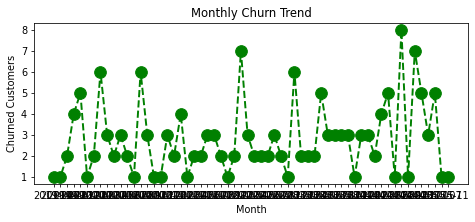

In [53]:
# 4.1 Monthly Churn Trend (Time Series KPI)

df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')

churn_trend = df_visual[df_visual['churn_flag'] == 1].groupby('cancellation_month').size()

plt.figure(figsize=(8,3))
plt.plot(churn_trend.index.astype(str), churn_trend.values,  color='green', marker='o', linestyle='dashed',  linewidth=2, markersize=12)

plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()

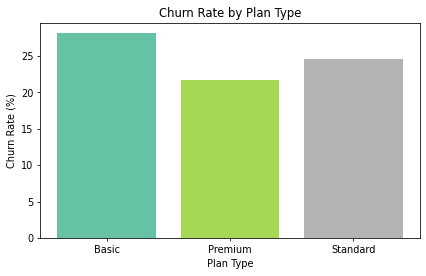

In [54]:
# 4.2 Churn Rate by Plan type
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean() * 100

# colors = ['yellow', 'purple', 'blue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize=(7,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn Rate by Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Churn Rate (%)')
plt.show()

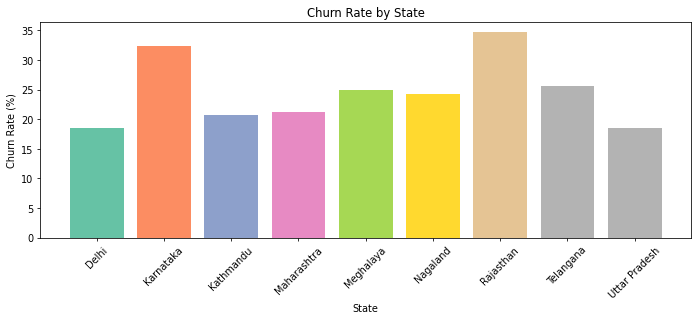

In [55]:
# 4.3 Churn by States
churn_plan = df_visual.groupby('state')['churn_flag'].mean() * 100

# colors = ['yellow', 'purple', 'blue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize=(12,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn Rate by State')
plt.xlabel('State')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.show()

## Visulaization using Seaborn

In [56]:
# Heatmap (Correlation Matrix)

In [57]:
# encoding - convert str to numeric so that we can find corr between features
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'customer_age', 'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='str')

In [58]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,0
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [59]:
# remove warnings
import warnings
warnings.filterwarnings("ignore")

In [60]:
# incorrect method of encoding - as numbers are not assigned based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

categorial_cols = ['plan_type', 'contract_type', 'churn_risk']

for col in categorial_cols:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes

<Axes: >

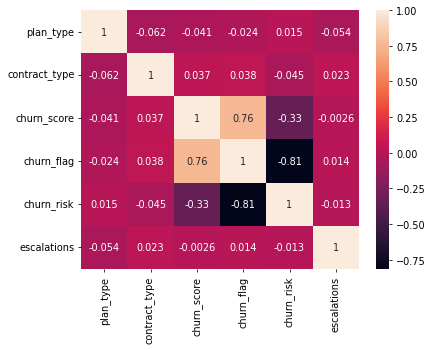

In [61]:
# Heatmap (correlation matrix)

sns.heatmap(df_encoded.corr(), annot=True)

In [62]:
print('plan_type :', df_visual['plan_type'].unique())
print('contract_type :', df_visual['contract_type'].unique())
print('churn_risk :', df_visual['churn_risk'].unique())

plan_type : <StringArray>
['Standard', 'Premium', 'Basic']
Length: 3, dtype: str
contract_type : <StringArray>
['Annual', 'Monthly']
Length: 2, dtype: str
churn_risk : <StringArray>
['low', 'high', 'med']
Length: 3, dtype: str


In [63]:
# Correct method of encoding - based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

order_mappings = {
    'plan_type' : ['Basic', 'Standard', 'Premium'],
    'contract_type' : ['Monthly', 'Annual'],
    'churn_risk': ['low', 'med', 'high']
    }

for col, order in order_mappings.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes

In [64]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,0
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [65]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,0,0
1,2,1,91,1,2,0
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,2,1


<Axes: >

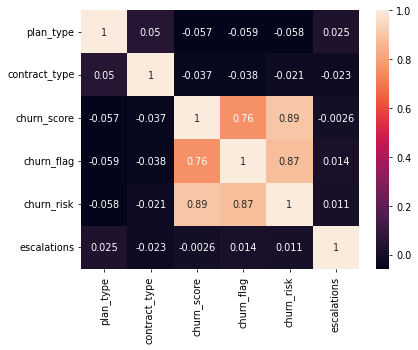

In [66]:
# Heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(), annot=True)

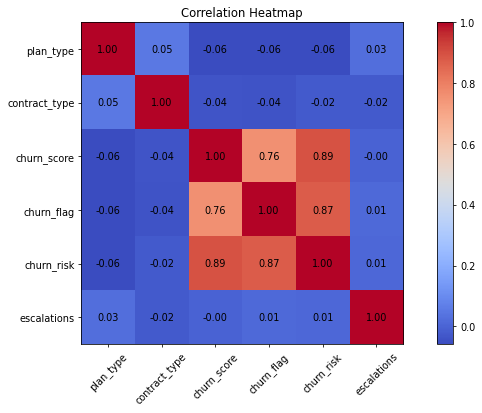

In [67]:
# Heatmap Using Matplotlib - difficult to plot it

corr_matrix = df_encoded.corr() # Correlation matrix

fig, ax = plt.subplots(figsize=(10, 6)) # Create figure

cax = ax.imshow(corr_matrix, cmap='coolwarm') # Heatmap

fig.colorbar(cax) # Add colorbar

# Axis labels
ax.set_xticks(np.arange(len(corr_matrix.columns)))
ax.set_yticks(np.arange(len(corr_matrix.columns)))

ax.set_xticklabels(corr_matrix.columns, rotation=45)
ax.set_yticklabels(corr_matrix.columns)

# Annotate values inside cells
for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        ax.text(
            j,
            i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha='center',
            va='center'
        )

plt.title('Correlation Heatmap') # Title

plt.tight_layout()
plt.show()

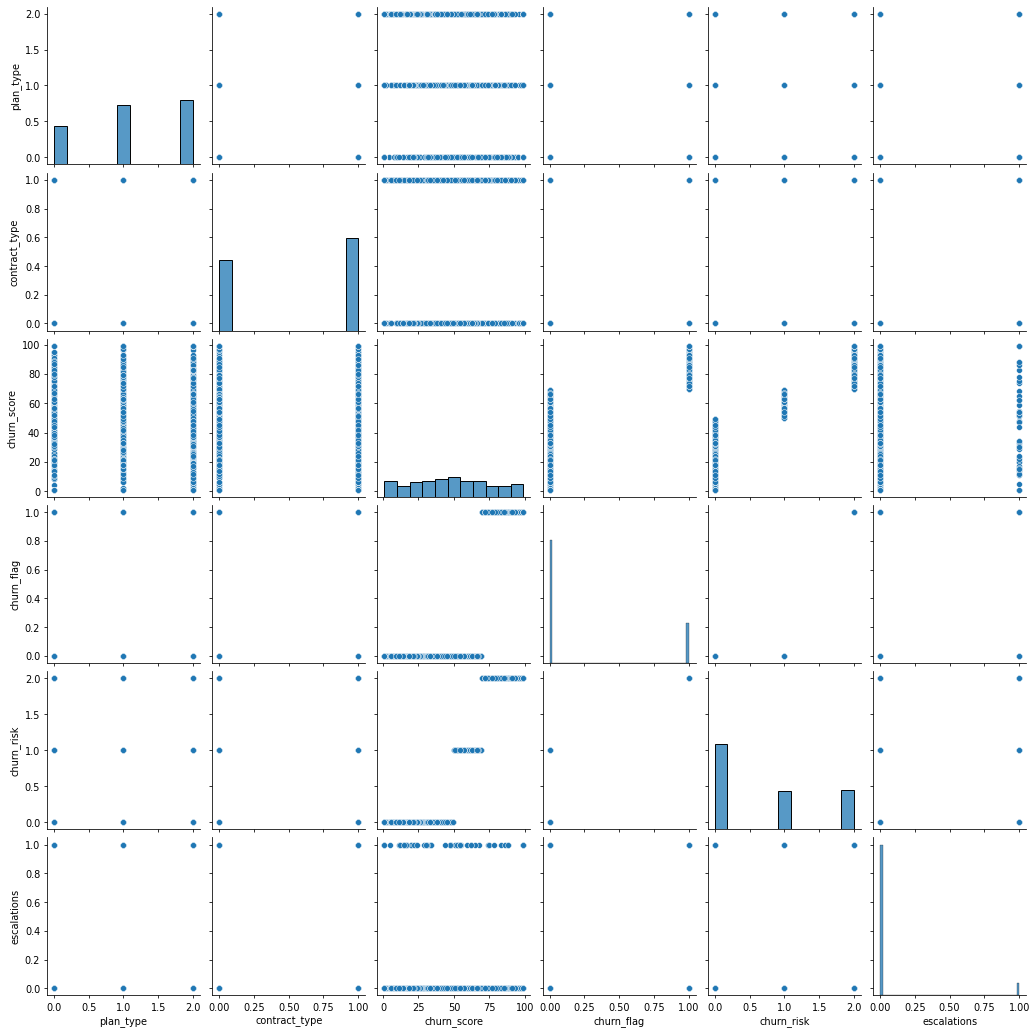

In [68]:
# pairplot - Plot pairwise relationships in a dataset
sns.pairplot(df_encoded)

In [69]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'customer_age', 'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='str')

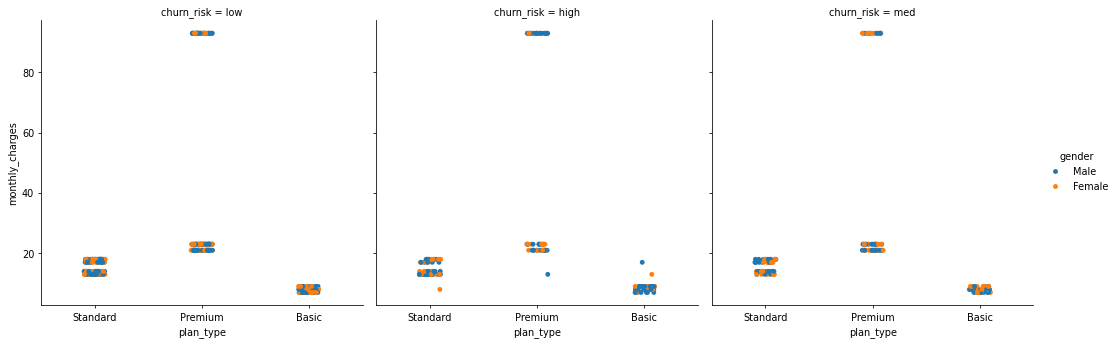

In [70]:
# catplt/Facegrid plot - multi-dim comparison

sns.catplot(data=df_visual,
    x='plan_type',
    y='monthly_charges',
    hue='gender',
    col='churn_risk')

## Pivot table

In [71]:
# Pivot Table

pd.pivot_table(
    df_visual,
    index='plan_type',
    values='churn_flag',
    aggfunc = 'mean'
)

,churn_flag
plan_type,
Basic,0.281437
Premium,0.216606
Standard,0.246094


In [72]:
# pivot table using multiple cols and agg type

pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges', 'customerid', 'churn_flag'],
    aggfunc = {
        'monthly_charges' : 'sum',
        'customerid' : 'nunique',
        'churn_flag' : 'mean'
    }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.281437,167,1349.33
Premium,0.216606,277,13548.23
Standard,0.246094,256,3894.44


## 5. Additional Analysis (added by Karan Shinde)
Extra analysis on **contract type, cancellation reasons, revenue share, and churn-risk segments**, plus a short summary of key findings.

In [73]:
# 5.1 Churn rate by contract type
churn_by_contract = (df.groupby('contract_type')
                       .agg(customers=('customerid', 'nunique'),
                            churned=('churn_flag', 'sum'),
                            churn_rate_pct=('churn_flag', lambda x: round(x.mean() * 100, 2)))
                       .reset_index())
print(churn_by_contract)

  contract_type  customers  churned  churn_rate_pct
0        Annual        398       91           22.86
1       Monthly        302       79           26.16


cancellation_reason
Switched to competitor    45
Forgot to cancel trial    38
Not enough content        33
Too expensive             30
Poor streaming quality    24
Name: count, dtype: int64


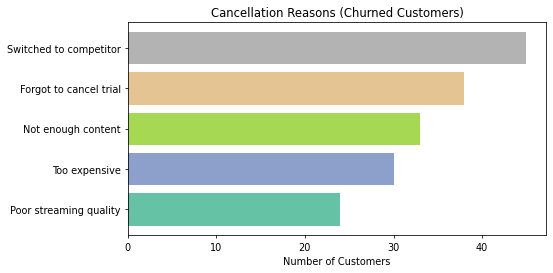

In [74]:
# 5.2 Cancellation reasons (churned customers only)
reasons = df.loc[df['churn_flag'] == 1, 'cancellation_reason'].value_counts()
print(reasons)

plt.figure(figsize=(8, 4))
plt.barh(reasons.index[::-1], reasons.values[::-1],
         color=plt.cm.Set2(np.linspace(0, 1, len(reasons))))
plt.title('Cancellation Reasons (Churned Customers)')
plt.xlabel('Number of Customers')
plt.tight_layout()
plt.show()

In [75]:
# 5.3 Revenue share by plan type
revenue_by_plan = (df.groupby('plan_type')['monthly_charges'].sum().round(2)
                     .sort_values(ascending=False).reset_index(name='total_monthly_charges'))
revenue_by_plan['share_pct'] = (revenue_by_plan['total_monthly_charges'] /
                                revenue_by_plan['total_monthly_charges'].sum() * 100).round(2)
print(revenue_by_plan)

  plan_type  total_monthly_charges  share_pct
0   Premium               13548.23      72.10
1  Standard                3894.44      20.72
2     Basic                1349.33       7.18


In [76]:
# 5.4 Churn-risk segments - customers and average monthly charges
risk_summary = (df.groupby('churn_risk')
                  .agg(customers=('customerid', 'nunique'),
                       churn_rate_pct=('churn_flag', lambda x: round(x.mean() * 100, 2)),
                       avg_monthly_charges=('monthly_charges', 'mean'))
                  .round(2)
                  .reset_index())
print(risk_summary)

  churn_risk  customers  churn_rate_pct  avg_monthly_charges
0       high        170           100.0                26.83
1        low        365             0.0                27.33
2        med        165             0.0                25.80


### Key Findings (700 customers)
- **Churn rate: 24.29%** (170 of 700 customers), so retention is 75.71%.
- **Basic plan has the highest churn (28.14%)**; Premium has the lowest (21.66%).
- **Monthly contracts churn more (26.16%)** than annual contracts (22.86%).
- **Premium customers bring about 72% of monthly revenue**, so retaining them matters most.
- Top cancellation reason: **switched to competitor**, followed by forgetting to cancel a trial and not enough content.
- About **24% of monthly revenue** (4,561.30) is lost from churned customers.
- Support escalations show almost no correlation with churn (0.01).

## Project Completed :)

In [77]:
# Project Completed Here. All the best! :)